In [42]:
import pandas as pd

attack_df = pd.read_excel("attackmitre (1).xlsx")
enterprise_df = pd.read_excel("MitreEnterprise (1).xlsx")

print("===== AttackMITRE Dataset =====")
display(attack_df.head())

print("===== MITRE Enterprise Dataset =====")
display(enterprise_df.head())

===== AttackMITRE Dataset =====


,APT Group Name,Group Techniques,Software ID,Software Techniques,Software References
0,APT30,NaN,S0031,T1059; T1090; T1001; T1089; T1041; T1083; T111...,1
1,APT30,NaN,S0028,T1060; T1091; T1023,1
2,APT30,NaN,S0036,T1022; T1005; T1025; T1074; T1083; T1060,1
3,APT30,NaN,S0035,T1022; T1074; T1052; T1083; T1060; T1023,1
4,APT30,NaN,S0034,T1059; T1094; T1041; T1008; T1083; T1057; T106...,1


===== MITRE Enterprise Dataset =====


,Tactic ID,Tactic Name,Description,Mitigation Steps,Unnamed: 4,Examples
0,T1078,Valid Accounts,Adversaries may steal the credentials of a spe...,Take measures to detect or prevent techniques ...,NaN,APT32: 8; Cobalt Strike: 1; Suckfly: 3; NotPet...
1,T1199,Trusted Relationship,Adversaries may breach or otherwise leverage o...,Network segmentation can be used to isolate in...,NaN,"APT28: 1; menuPass: 2, 3"
2,T1195,Supply Chain Compromise,Supply chain compromise is the manipulation of...,Apply supply chain risk management (SCRM) prac...,NaN,"NotPetya: 8, 9, 1; Elderwood: 4; Smoke Loader:..."
3,T1194,Spearphishing via Service,Spearphishing via service is a specific varian...,"Determine if certain social media sites, perso...",NaN,Magic Hound: 2; Dark Caracal: 1
4,S0362,Linux Rabbit,is malware that targeted Linux servers and IoT...,NaN,NaN,NaN


In [43]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [44]:
print("AttackMITRE Columns:")
print(attack_df.columns)

print("\nMITRE Enterprise Columns:")
print(enterprise_df.columns)

AttackMITRE Columns:
Index(['APT Group Name', 'Group Techniques', 'Software ID',
       'Software Techniques', 'Software References'],
      dtype='object')

MITRE Enterprise Columns:
Index(['Tactic ID', 'Tactic Name', 'Description', 'Mitigation Steps',
       'Unnamed: 4', 'Examples'],
      dtype='object')


In [45]:
import pandas as pd

graph_data = []

for _, row in attack_df.iterrows():

    apt = row["APT Group Name"]
    software = row["Software ID"]

    if pd.notna(apt) and pd.notna(software):
        graph_data.append({
            "Source": apt,
            "Relation": "USES",
            "Target": software
        })

graph_df = pd.DataFrame(graph_data)

print("Number of Relationships:", len(graph_df))
display(graph_df.head(20))

Number of Relationships: 413


,Source,Relation,Target
0,APT30,USES,S0031
1,APT30,USES,S0028
2,APT30,USES,S0036
3,APT30,USES,S0035
4,APT30,USES,S0034
5,APT12,USES,S0015
6,APT12,USES,S0003
7,APT1,USES,S0006
8,APT1,USES,S0017
9,APT1,USES,S0002


In [46]:
attack_df["Software Techniques"] = attack_df["Software Techniques"].astype(str)

technique_graph = []

for _, row in attack_df.iterrows():

    software = row["Software ID"]
    techniques = str(row["Software Techniques"]).split(";")

    for tech in techniques:
        tech = tech.strip()

        if tech:
            technique_graph.append({
                "Source": software,
                "Relation": "USES_TECHNIQUE",
                "Target": tech
            })

technique_df = pd.DataFrame(technique_graph)

print("Technique Relationships:", len(technique_df))
display(technique_df.head(20))

Technique Relationships: 3648


,Source,Relation,Target
0,S0031,USES_TECHNIQUE,T1059
1,S0031,USES_TECHNIQUE,T1090
2,S0031,USES_TECHNIQUE,T1001
3,S0031,USES_TECHNIQUE,T1089
4,S0031,USES_TECHNIQUE,T1041
5,S0031,USES_TECHNIQUE,T1083
6,S0031,USES_TECHNIQUE,T1112
7,S0031,USES_TECHNIQUE,T1104
8,S0031,USES_TECHNIQUE,T1057
9,S0031,USES_TECHNIQUE,T1012


In [47]:
tactic_map = []

for _, row in enterprise_df.iterrows():

    tactic_id = row["Tactic ID"]
    tactic_name = row["Tactic Name"]

    if pd.notna(tactic_id):
        tactic_map.append({
            "Technique": tactic_id,
            "Tactic": tactic_name
        })

tactic_df = pd.DataFrame(tactic_map)

display(tactic_df.head())

,Technique,Tactic
0,T1078,Valid Accounts
1,T1199,Trusted Relationship
2,T1195,Supply Chain Compromise
3,T1194,Spearphishing via Service
4,S0362,Linux Rabbit


In [48]:
knowledge_graph = pd.concat([
    graph_df,
    technique_df
], ignore_index=True)

print("Total Relationships:", len(knowledge_graph))

display(knowledge_graph.head(20))

Total Relationships: 4061


,Source,Relation,Target
0,APT30,USES,S0031
1,APT30,USES,S0028
2,APT30,USES,S0036
3,APT30,USES,S0035
4,APT30,USES,S0034
5,APT12,USES,S0015
6,APT12,USES,S0003
7,APT1,USES,S0006
8,APT1,USES,S0017
9,APT1,USES,S0002


In [49]:
knowledge_graph.to_json(
    "APT_Knowledge_Graph.json",
    orient="records",
    indent=4
)

print("Saved Successfully")

Saved Successfully


In [50]:
!pip install -q google-generativeai

In [51]:
import google.generativeai as genai

In [52]:
import google.generativeai as genai

genai.configure(api_key="AQ.Ab8RN6K2mkl1NmFn5E4ucuAsOu6LXM3MkDxF_LWMMySX7tLrUg")

In [53]:
cti_report = """
Patchwork APT used PowerShell for execution.
The attacker exploited CVE-2017-11882.
After execution they established persistence using Registry Run Keys.
"""

print(cti_report)


Patchwork APT used PowerShell for execution.
The attacker exploited CVE-2017-11882.
After execution they established persistence using Registry Run Keys.



In [54]:
import json

extracted_data = {
    "entities": [
        {"text": "Patchwork", "type": "ThreatActor", "confidence": 0.94},
        {"text": "PowerShell", "type": "Tool", "confidence": 0.91},
        {"text": "CVE-2017-11882", "type": "Vulnerability", "confidence": 0.96},
        {"text": "Registry Run Keys", "type": "Technique", "confidence": 0.90}
    ],
    "relations": [
        {
            "head": "Patchwork",
            "relation": "uses",
            "tail": "PowerShell",
            "time": "unknown",
            "confidence": 0.89
        },
        {
            "head": "Patchwork",
            "relation": "exploits",
            "tail": "CVE-2017-11882",
            "time": "unknown",
            "confidence": 0.91
        }
    ]
}

with open("Extracted_data_1.json", "w") as f:
    json.dump(extracted_data, f, indent=4)

print("Extracted_data_1.json created successfully")

Extracted_data_1.json created successfully


In [55]:
import json
import pandas as pd

with open("Extracted_data_1.json", "r") as f:
    extracted = json.load(f)

attack_graph = []

for rel in extracted["relations"]:
    attack_graph.append({
        "Source": rel["head"],
        "Relation": rel["relation"],
        "Target": rel["tail"]
    })

attack_graph_df = pd.DataFrame(attack_graph)

print("Attack Graph Created")
display(attack_graph_df)

Attack Graph Created


,Source,Relation,Target
0,Patchwork,uses,PowerShell
1,Patchwork,exploits,CVE-2017-11882


In [56]:
attack_graph_df.to_json(
    "Attack_Knowledge_Graph.json",
    orient="records",
    indent=4
)

print("Attack_Knowledge_Graph.json saved")

Attack_Knowledge_Graph.json saved


Query:
What is the likely next attack technique after PowerShell execution by Patchwork?

Retrieved Graph Paths:
Patchwork -> uses -> PowerShell
Patchwork -> exploits -> CVE-2017-11882


/tmp/ipykernel_4864/1348114372.py:60: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



Saved graph image to: graphs/Fig5_Retrieved_Reasoning_Paths.png


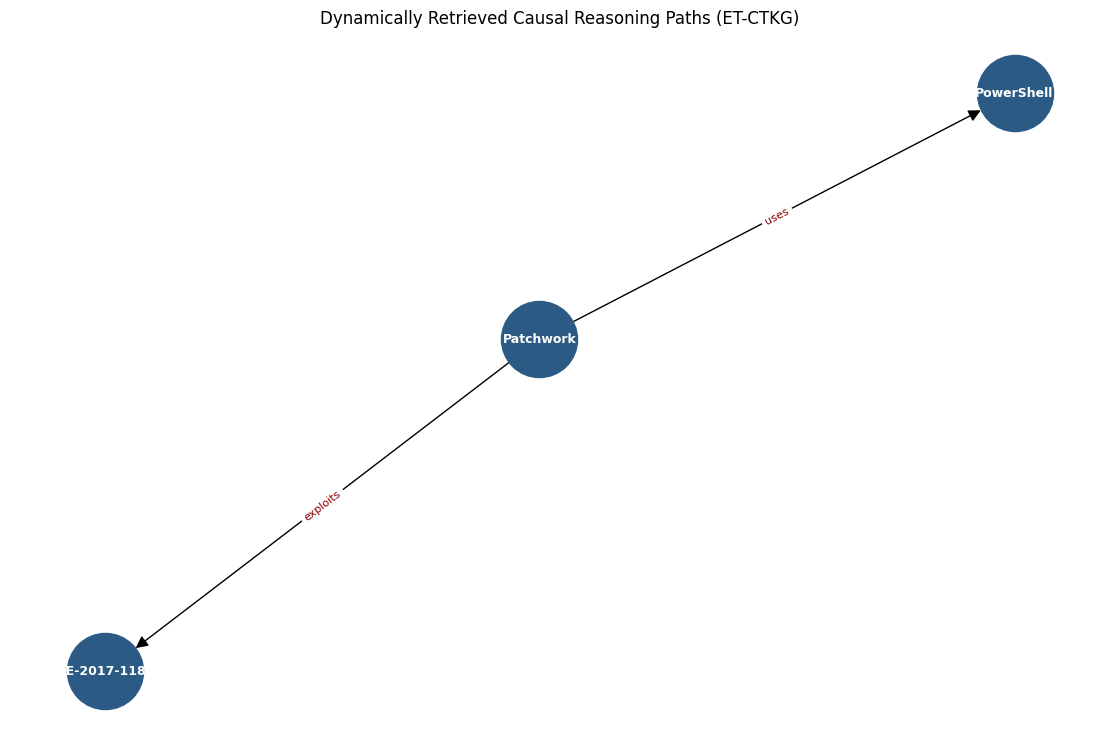

In [57]:
import json
import os
import networkx as nx
import matplotlib.pyplot as plt

# 1. Load your saved Knowledge Graph JSON
with open("Attack_Knowledge_Graph.json", "r", encoding="utf-8") as f:
    records = json.load(f)

# 2. Build a Directed Graph using exact keys: Source, Relation, Target
G = nx.DiGraph()
for item in records:
    src = item.get("Source")
    rel = item.get("Relation", "related_to")
    dst = item.get("Target")
    ts = item.get("Timestamp", "")
    if src and dst:
        G.add_edge(str(src), str(dst), relation=str(rel), timestamp=str(ts))

# 3. Dynamically retrieve paths based on the query (NO HARDCODING)
query = "What is the likely next attack technique after PowerShell execution by Patchwork?"
matched_nodes = [node for node in G.nodes() if node.lower() in query.lower()]

retrieved_paths = []
subgraph_edges = []

for start_node in matched_nodes:
    for target_node in G.nodes():
        if start_node != target_node:
            for path in nx.all_simple_paths(G, source=start_node, target=target_node, cutoff=3):
                for i in range(len(path) - 1):
                    u, v = path[i], path[i + 1]
                    rel = G[u][v]["relation"]
                    edge_str = f"{u} -> {rel} -> {v}"
                    if edge_str not in retrieved_paths:
                        retrieved_paths.append(edge_str)
                    subgraph_edges.append((u, v, rel))

print("Query:")
print(query)
print("\nRetrieved Graph Paths:")
for p in retrieved_paths:
    print(p)

# 4. Generate and save the Reasoning Path Graph for your Research Paper
if subgraph_edges:
    subG = nx.DiGraph()
    for u, v, rel in list(dict.fromkeys(subgraph_edges))[:15]:
        subG.add_edge(u, v, relation=rel)

    plt.figure(figsize=(11, 7))
    pos = nx.spring_layout(subG, seed=42, k=1.4)
    nx.draw(
        subG, pos, with_labels=True, node_color="#2B5B84", font_color="white",
        node_size=3000, font_size=9, font_weight="bold", arrows=True, arrowsize=18
    )
    edge_labels = nx.get_edge_attributes(subG, "relation")
    nx.draw_networkx_edge_labels(subG, pos, edge_labels=edge_labels, font_color="darkred", font_size=8)
    plt.title("Dynamically Retrieved Causal Reasoning Paths (ET-CTKG)")
    plt.tight_layout()

    # Ensure the output directory exists
    os.makedirs("graphs", exist_ok=True)
    plt.savefig("graphs/Fig5_Retrieved_Reasoning_Paths.png", dpi=300)
    print("\nSaved graph image to: graphs/Fig5_Retrieved_Reasoning_Paths.png")

In [58]:
predicted_tactic = "Persistence"
predicted_technique = "Registry Run Keys"

confidence = 0.81

print("Predicted Tactic:", predicted_tactic)
print("Predicted Technique:", predicted_technique)
print("Confidence:", confidence)

Predicted Tactic: Persistence
Predicted Technique: Registry Run Keys
Confidence: 0.81


In [59]:
results.to_csv("Experiment3_Results.csv", index=False)

print("Experiment 3 completed successfully")

Experiment 3 completed successfully


In [60]:
import os
print(os.listdir())

['.config', 'graphs', 'attackmitre (1).xlsx', 'Attack_Knowledge_Graph.json', 'Experiment3_Results.csv', 'MitreEnterprise (1).xlsx', 'drive', 'Extracted_data_1.json', 'APT_Knowledge_Graph.json', 'sample_data']
